Market Basket Analysis (Cross-Selling Strategy) Bagian Pemodelan

In [8]:
#0. Setup & Impor Library
import os, time, pickle, tracemalloc, warnings, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mlxtend
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)
RANDOM_STATE = 42

print("mlxtend :", mlxtend.__version__)
print("pandas  :", pd.__version__)
print("numpy   :", np.__version__)

mlxtend : 0.25.0
pandas  : 3.0.2
numpy   : 2.4.4


In [9]:
#1. Load Data
DATA_PATH   = "../data/Groceries_dataset.csv"   # raw data asli
PERAN2_CSV  = "../data/Groceries_encoded.csv"   # <- output Peran 2 
USE_SYNTHETIC = False

def make_synthetic(n_tx=14000, seed=RANDOM_STATE):
    # HANYA untuk uji kode bila dataset asli belum ada.
    rng = np.random.default_rng(seed)
    items = [f"item_{i:03d}" for i in range(160)]
    pop = np.arange(1, 161, dtype=float) ** -1.0
    pop /= pop.sum()
    pairs = [("item_010", "item_011"), ("item_020", "item_021"), ("item_030", "item_031"),
            ("item_040", "item_041"), ("item_050", "item_051")]
    rows = []
    for t in range(n_tx):
        k = max(1, int(rng.poisson(2.6)))
        basket = set(rng.choice(items, size=k, p=pop))
        for a, b in pairs:
            if rng.random() < 0.025:
                basket |= {a, b}
        for it in basket:
            rows.append((t, "2015-01-01", it))
    return pd.DataFrame(rows, columns=["Member_number", "Date", "itemDescription"])

if os.path.exists(PERAN2_CSV):
    print("Memakai output Peran 2:", PERAN2_CSV)
    basket = pd.read_csv(PERAN2_CSV, index_col=0)  # baris = transaction_id, kolom = produk, nilai 0/1
    SOURCE = "peran2"
else:
    if os.path.exists(DATA_PATH):
        raw = pd.read_csv(DATA_PATH)
        SOURCE = "groceries"
    else:
        print("!!! DATASET TIDAK DITEMUKAN -> memakai DATA SINTETIS (hanya uji kode) !!!")
        raw = make_synthetic()
        USE_SYNTHETIC = True
        SOURCE = "synthetic"
    print("Dimensi data mentah:", raw.shape)
    display(raw.head())

Memakai output Peran 2: ../data/Groceries_encoded.csv


In [10]:
# 2. Membentuk Matriks Keranjang (One-Hot)
if SOURCE != "peran2":
    raw = raw.dropna(subset=["Member_number", "Date", "itemDescription"]).copy()
    raw["itemDescription"] = raw["itemDescription"].astype(str).str.lower().str.strip().str.replace(r"\s+", " ", regex=True)

    transactions = (raw.groupby(["Member_number", "Date"])["itemDescription"]
                       .apply(lambda s: sorted(set(s)))
                       .tolist())
    n_before = len(transactions)
    transactions = [t for t in transactions if len(t) >= 2]
    print(f"Transaksi sebelum filter : {n_before:,}")
    print(f"Transaksi >= 2 item      : {len(transactions):,}  (dibuang: {n_before-len(transactions):,})")

    te = TransactionEncoder()
    basket = pd.DataFrame(te.fit(transactions).transform(transactions, sparse=False), columns=te.columns_)

basket = basket.astype(bool)
N_TX, N_ITEMS = basket.shape
print(f"\nMatriks keranjang: {N_TX:,} transaksi x {N_ITEMS:,} produk")
print("Rata-rata item/keranjang :", round(basket.sum(axis=1).mean(), 2))
print("Kepadatan (density)      :", f"{basket.values.mean():.4%}")
display(basket.iloc[:5, :8])


Matriks keranjang: 14,758 transaksi x 167 produk
Rata-rata item/keranjang : 2.56
Kepadatan (density)      : 1.5338%


,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries
transaction_id,,,,,,,,
1000_2014-06-24,False,False,False,False,False,False,False,False
1000_2015-03-15,False,False,False,False,False,False,False,False
1000_2015-05-27,False,False,False,False,False,False,False,False
1000_2015-07-24,False,False,False,False,False,False,False,False
1000_2015-11-25,False,False,False,False,False,False,False,False


In [ ]:
# 3. Fungsi Pengukur Waktu & Memori
ALGO = {"Apriori": apriori, "FP-Growth": fpgrowth}

def jalankan(nama, min_support, df=basket, n_ulang=3, max_len=None):
    fn = ALGO[nama]
    waktu = []
    for _ in range(n_ulang):
        t0 = time.perf_counter()
        hasil = fn(df, min_support=min_support, use_colnames=True, max_len=max_len)
        waktu.append(time.perf_counter() - t0)
    # satu run terpisah untuk memori (tracemalloc memperlambat eksekusi)
    tracemalloc.start()
    fn(df, min_support=min_support, use_colnames=True, max_len=max_len)
    _, puncak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return hasil, {
        "algoritma": nama,
        "min_support": min_support,
        "n_itemsets": len(hasil),
        "waktu_detik": float(np.median(waktu)),
        "memori_puncak_MB": puncak / 1024**2,
    }

# uji cepat
_, info = jalankan("FP-Growth", 0.02, n_ulang=1)
info

{'algoritma': 'FP-Growth',
 'min_support': 0.02,
 'n_itemsets': 38,
 'waktu_detik': 0.4872823000187054,
 'memori_puncak_MB': 4.770988464355469}

In [12]:
# 4. Eksperimen `min_support`: Apriori vs FP-Growth
GRID_SUPPORT = [0.001, 0.0025, 0.005, 0.01, 0.02]

catatan, simpan_itemsets = [], {}
for s in GRID_SUPPORT:
    for nama in ALGO:
        hasil, info = jalankan(nama, s)
        catatan.append(info)
        simpan_itemsets[(nama, s)] = hasil
        print(f"{nama:10s} min_support={s:<7} -> {info['n_itemsets']:>6} itemsets | "
              f"{info['waktu_detik']:.3f} dtk | {info['memori_puncak_MB']:.1f} MB")

hasil_eksp = pd.DataFrame(catatan)
tabel = (hasil_eksp.pivot(index="min_support", columns="algoritma",
                          values=["n_itemsets", "waktu_detik", "memori_puncak_MB"]))
tabel

Apriori    min_support=0.001   ->    750 itemsets | 1.310 dtk | 468.2 MB
FP-Growth  min_support=0.001   ->    750 itemsets | 0.168 dtk | 5.4 MB
Apriori    min_support=0.0025  ->    267 itemsets | 0.554 dtk | 294.0 MB
FP-Growth  min_support=0.0025  ->    267 itemsets | 0.229 dtk | 5.2 MB
Apriori    min_support=0.005   ->    130 itemsets | 0.353 dtk | 171.6 MB
FP-Growth  min_support=0.005   ->    130 itemsets | 0.319 dtk | 4.8 MB
Apriori    min_support=0.01    ->     69 itemsets | 0.227 dtk | 87.6 MB
FP-Growth  min_support=0.01    ->     69 itemsets | 0.289 dtk | 4.8 MB
Apriori    min_support=0.02    ->     38 itemsets | 0.141 dtk | 32.2 MB
FP-Growth  min_support=0.02    ->     38 itemsets | 0.240 dtk | 4.8 MB


n_itemsets           waktu_detik           memori_puncak_MB          
algoritma      Apriori FP-Growth     Apriori FP-Growth          Apriori FP-Growth
min_support                                                                      
0.0010           750.0     750.0    1.310466  0.167982       468.190032  5.360223
0.0025           267.0     267.0    0.553817  0.228888       294.041314  5.161569
0.0050           130.0     130.0    0.353325  0.318783       171.634480  4.783219
0.0100            69.0      69.0    0.227401  0.289358        87.622233  4.770988
0.0200            38.0      38.0    0.140655  0.239568        32.163033  4.770988

In [13]:
# 5. Verifikasi
cek = []
for s in GRID_SUPPORT:
    a = simpan_itemsets[("Apriori", s)].copy()
    f = simpan_itemsets[("FP-Growth", s)].copy()
    a = a.set_index(a["itemsets"].apply(frozenset))["support"]
    f = f.set_index(f["itemsets"].apply(frozenset))["support"]
    sama_set = set(a.index) == set(f.index)
    selisih = float((a - f.reindex(a.index)).abs().max()) if sama_set else np.nan
    cek.append({"min_support": s, "n_apriori": len(a), "n_fpgrowth": len(f),
                "identik": sama_set, "selisih_support_maks": selisih})
pd.DataFrame(cek)

,min_support,n_apriori,n_fpgrowth,identik,selisih_support_maks
0,0.0010,750,750,True,0.0
1,0.0025,267,267,True,0.0
2,0.0050,130,130,True,0.0
3,0.0100,69,69,True,0.0
4,0.0200,38,38,True,0.0


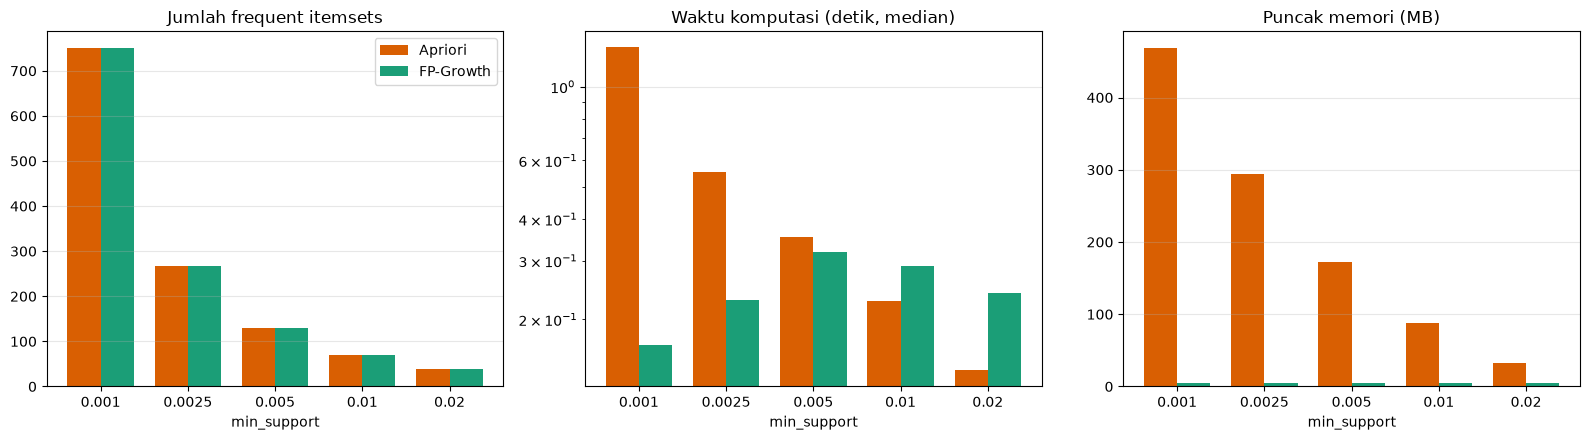

In [14]:
# 6. Visualisasi Perbandingan
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
metrik = [("n_itemsets", "Jumlah frequent itemsets", False),
          ("waktu_detik", "Waktu komputasi (detik, median)", True),
          ("memori_puncak_MB", "Puncak memori (MB)", False)]
warna = {"Apriori": "#d95f02", "FP-Growth": "#1b9e77"}
xs = [str(s) for s in GRID_SUPPORT]
lebar = 0.38
for a_, (kol, judul, log) in zip(ax, metrik):
    for i, nama in enumerate(ALGO):
        v = hasil_eksp[hasil_eksp.algoritma == nama].sort_values("min_support")[kol].values
        a_.bar(np.arange(len(xs)) + (i - 0.5) * lebar, v, lebar, label=nama, color=warna[nama])
    a_.set_xticks(range(len(xs))); a_.set_xticklabels(xs)
    a_.set_xlabel("min_support"); a_.set_title(judul)
    if log: a_.set_yscale("log")
    a_.grid(axis="y", alpha=.3)
ax[0].legend()
plt.tight_layout(); plt.show()

In [15]:
# 7. Memilih `min_support` Final
ringkas = []
for s in GRID_SUPPORT:
    it = simpan_itemsets[("FP-Growth", s)]
    ukuran = it["itemsets"].apply(len)
    ringkas.append({"min_support": s,
                    "transaksi_minimal": int(np.ceil(s * N_TX)),
                    "itemset_1": int((ukuran == 1).sum()),
                    "itemset_2": int((ukuran == 2).sum()),
                    "itemset_3+": int((ukuran >= 3).sum())})
display(pd.DataFrame(ringkas))

MIN_SUPPORT = 0.001      # <- keputusan final (0,1% = minimal ~15 transaksi); lihat alasan di sel markdown berikutnya
print(f"\nMIN_SUPPORT final = {MIN_SUPPORT}  (= minimal {int(np.ceil(MIN_SUPPORT*N_TX))} transaksi)")

,min_support,transaksi_minimal,itemset_1,itemset_2,itemset_3+
0,0.0010,15,149,592,9
1,0.0025,37,118,149,0
2,0.0050,74,90,40,0
3,0.0100,148,64,5,0
4,0.0200,296,38,0,0



MIN_SUPPORT final = 0.001  (= minimal 15 transaksi)


In [16]:
# 8. Association Rules & Tuning `min_confidence`
itemsets_final = fpgrowth(basket, min_support=MIN_SUPPORT, use_colnames=True)
print("Frequent itemsets final:", len(itemsets_final))

def buat_rules(itemsets, metric="confidence", min_threshold=0.1):
    params = inspect.signature(association_rules).parameters
    kw = dict(metric=metric, min_threshold=min_threshold)
    if "num_itemsets" in params:           # mlxtend baru
        kw["num_itemsets"] = N_TX
    return association_rules(itemsets, **kw)

# Rules "mentah" dengan ambang sangat rendah
rules_all = buat_rules(itemsets_final, "confidence", 0.0)
print("Total rules (confidence >= 0):", len(rules_all))

# Tuning min_confidence
grid_conf = [0.03, 0.05, 0.08, 0.10, 0.20]
tuning = []
for c in grid_conf:
    r = rules_all[rules_all["confidence"] >= c]
    tuning.append({"min_confidence": c, "n_rules": len(r),
                   "n_lift>1": int((r["lift"] > 1).sum()),
                   "n_lift>1.2": int((r["lift"] > 1.2).sum()),
                   "lift_median": round(float(r["lift"].median()), 2) if len(r) else np.nan})
pd.DataFrame(tuning)

Frequent itemsets final: 750
Total rules (confidence >= 0): 1238


,min_confidence,n_rules,n_lift>1,n_lift>1.2,lift_median
0,0.03,812,160,58,0.84
1,0.05,454,94,38,0.84
2,0.08,235,55,25,0.85
3,0.10,133,38,15,0.88
4,0.20,2,2,2,1.49


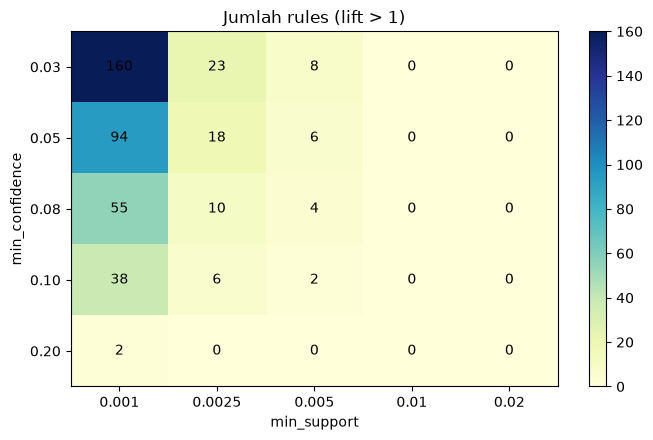

In [17]:
# 8b. Sensitivitas: kombinasi `min_support` × `min_confidence`
peta = pd.DataFrame(index=[f"{c:.2f}" for c in grid_conf], columns=[str(s) for s in GRID_SUPPORT], dtype=float)
for s in GRID_SUPPORT:
    its = simpan_itemsets[("FP-Growth", s)]
    try:
        r = buat_rules(its, "confidence", 0.0)
    except Exception:
        r = pd.DataFrame({"confidence": [], "lift": []})
    for c in grid_conf:
        peta.loc[f"{c:.2f}", str(s)] = int(((r["confidence"] >= c) & (r["lift"] > 1)).sum()) if len(r) else 0

fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(peta.values.astype(float), cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(peta.shape[1])); ax.set_xticklabels(peta.columns)
ax.set_yticks(range(peta.shape[0])); ax.set_yticklabels(peta.index)
ax.set_xlabel("min_support"); ax.set_ylabel("min_confidence"); ax.set_title("Jumlah rules (lift > 1)")
for i in range(peta.shape[0]):
    for j in range(peta.shape[1]):
        ax.text(j, i, int(peta.values[i, j]), ha="center", va="center", fontsize=10)
plt.colorbar(im); plt.tight_layout(); plt.show()

In [18]:
# 8c. Menetapkan Rules Final
MIN_CONFIDENCE = 0.05    
MIN_LIFT       = 1.0     

rules = rules_all[(rules_all["confidence"] >= MIN_CONFIDENCE) & (rules_all["lift"] > MIN_LIFT)].copy()
rules["antecedents_str"] = rules["antecedents"].apply(lambda s: ", ".join(sorted(s)))
rules["consequents_str"] = rules["consequents"].apply(lambda s: ", ".join(sorted(s)))
rules["n_antecedents"]   = rules["antecedents"].apply(len)
rules = rules.sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True)

print(f"Rules final: {len(rules)}  (min_support={MIN_SUPPORT}, min_confidence={MIN_CONFIDENCE}, lift>{MIN_LIFT})")
print("Tidak ada rules? Turunkan MIN_SUPPORT / MIN_CONFIDENCE.") if len(rules) == 0 else None

Rules final: 94  (min_support=0.001, min_confidence=0.05, lift>1.0)


In [19]:
# 9. Tabel Rules Teratas
rules["n_transaksi"] = (rules["support"] * N_TX).round().astype(int)
kolom = ["antecedents_str", "consequents_str", "n_transaksi", "support", "confidence", "lift", "leverage", "conviction"]
top = rules[kolom].head(15).copy()
top[["support", "confidence", "lift", "leverage"]] = top[["support", "confidence", "lift", "leverage"]].round(4)
top["conviction"] = top["conviction"].round(3)
top

,antecedents_str,consequents_str,n_transaksi,support,confidence,lift,leverage,conviction
0,"whole milk, yogurt",sausage,22,0.0015,0.1317,2.1578,0.0008,1.081
1,"sausage, whole milk",yogurt,22,0.0015,0.1642,1.9078,0.0007,1.093
2,specialty chocolate,citrus fruit,21,0.0014,0.0879,1.6394,0.0006,1.038
3,"sausage, yogurt",whole milk,22,0.0015,0.2558,1.6252,0.0006,1.132
4,flour,tropical fruit,16,0.0011,0.1096,1.5997,0.0004,1.046
5,beverages,sausage,23,0.0016,0.0931,1.5252,0.0005,1.035
6,"soda, whole milk",sausage,16,0.0011,0.0920,1.5062,0.0004,1.034
7,napkins,pastry,26,0.0018,0.0788,1.5062,0.0006,1.029
8,processed cheese,root vegetables,16,0.0011,0.1053,1.5053,0.0004,1.039
9,soft cheese,yogurt,19,0.0013,0.1267,1.4719,0.0004,1.047


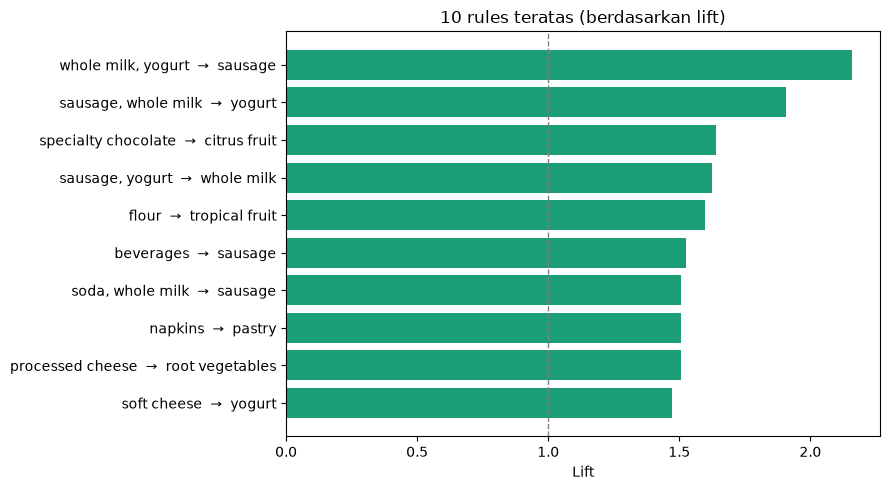

In [20]:
# Bar chart 10 rules teratas berdasarkan lift
t10 = rules.head(10).iloc[::-1]
etiket = t10["antecedents_str"] + "  →  " + t10["consequents_str"]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(etiket, t10["lift"], color="#1b9e77")
ax.axvline(1, color="gray", ls="--", lw=1)
ax.set_xlabel("Lift"); ax.set_title("10 rules teratas (berdasarkan lift)")
plt.tight_layout(); plt.show()

In [22]:
# 10. Menyimpan Hasil dengan Pickle
from datetime import datetime

bundle = {
    "rules": rules,
    "itemsets": itemsets_final,
    "daftar_item": sorted(basket.columns),
    "meta": {
        "algoritma": "FP-Growth",
        "min_support": MIN_SUPPORT,
        "min_confidence": MIN_CONFIDENCE,
        "min_lift": MIN_LIFT,
        "n_transaksi": N_TX,
        "n_item": N_ITEMS,
        "sumber_data": SOURCE,
        "dibuat": datetime.now().isoformat(timespec="seconds"),
        "versi": {"mlxtend": mlxtend.__version__, "pandas": pd.__version__, "numpy": np.__version__},
    },
}

os.makedirs("../models", exist_ok=True)
PKL_PATH = "../models/rules_bundle.pkl"
with open(PKL_PATH, "wb") as f:
    pickle.dump(bundle, f)

rules.drop(columns=["antecedents", "consequents"]).to_csv("../models/rules_final.csv", index=False)
hasil_eksp.to_csv("../models/perbandingan_apriori_fpgrowth.csv", index=False)

# Uji muat ulang
with open(PKL_PATH, "rb") as f:
    cek_bundle = pickle.load(f)
print("File     :", PKL_PATH, f"({os.path.getsize(PKL_PATH)/1024:.1f} KB)")
print("Isi      :", list(cek_bundle.keys()))
print("Jml rules:", len(cek_bundle["rules"]), "| sama dengan asli:", cek_bundle["rules"].equals(rules))
cek_bundle["meta"]

File     : ../models/rules_bundle.pkl (27.5 KB)
Isi      : ['rules', 'itemsets', 'daftar_item', 'meta']
Jml rules: 94 | sama dengan asli: True


{'algoritma': 'FP-Growth',
 'min_support': 0.001,
 'min_confidence': 0.05,
 'min_lift': 1.0,
 'n_transaksi': 14758,
 'n_item': 167,
 'sumber_data': 'peran2',
 'dibuat': '2026-11-28T14:28:42',
 'versi': {'mlxtend': '0.25.0', 'pandas': '3.0.2', 'numpy': '2.4.4'}}

In [23]:
# 11. Uji Fungsi Rekomendasi
def rekomendasi(keranjang, rules_df=rules, top_n=5):
    keranjang = {k.lower().strip() for k in keranjang}
    cocok = rules_df[rules_df["antecedents"].apply(lambda a: a.issubset(keranjang))]
    cocok = cocok[~cocok["consequents"].apply(lambda c: c.issubset(keranjang))]
    if cocok.empty:
        return pd.DataFrame(columns=["rekomendasi", "confidence", "lift", "karena"])
    out = (cocok.sort_values(["lift", "confidence"], ascending=False)
                .assign(rekomendasi=lambda d: d["consequents_str"], karena=lambda d: d["antecedents_str"])
                .drop_duplicates("rekomendasi")
                [["rekomendasi", "confidence", "lift", "karena"]]
                .head(top_n).round(3))
    return out.reset_index(drop=True)

# Uji dengan antecedent dari rule teratas
if len(rules):
    contoh = list(rules.loc[0, "antecedents"])
    print("Keranjang uji:", contoh)
    display(rekomendasi(contoh))

Keranjang uji: ['yogurt', 'whole milk']


,rekomendasi,confidence,lift,karena
0,sausage,0.132,2.158,"whole milk, yogurt"
1,rolls/buns,0.120,1.090,"whole milk, yogurt"
2,citrus fruit,0.054,1.014,yogurt


In [25]:
# 12. Kesimpuan Modeling & Rules
ref = hasil_eksp[hasil_eksp["min_support"] == MIN_SUPPORT].set_index("algoritma")
a, f = ref.loc["Apriori"], ref.loc["FP-Growth"]
kuat = rules[rules["lift"] >= 1.2]
best = rules.iloc[0]

ringkasan = pd.DataFrame({
    "Item": [
        "Dataset / transaksi / produk",
        "min_support yang diuji",
        "min_support final",
        "Frequent itemsets (final)",
        "Hasil Apriori vs FP-Growth",
        f"Waktu pada min_support {MIN_SUPPORT}",
        f"Memori puncak pada min_support {MIN_SUPPORT}",
        "min_confidence / lift minimal",
        "Jumlah rules final",
        "Rules dengan lift >= 1,2",
        "Rule terbaik (lift)",
    ],
    "Nilai": [
        f"{SOURCE} / {N_TX:,} transaksi / {N_ITEMS} produk",
        ", ".join(f"{s*100:g}%" for s in GRID_SUPPORT),
        f"{MIN_SUPPORT*100:g}% (minimal {int(np.ceil(MIN_SUPPORT*N_TX))} transaksi)",
        f"{len(itemsets_final)}",
        "identik" if all(c["identik"] for c in cek) else "TIDAK identik, periksa tahap 5",
        f"Apriori {a['waktu_detik']:.3f} dtk vs FP-Growth {f['waktu_detik']:.3f} dtk ({a['waktu_detik']/f['waktu_detik']:.1f}x)",
        f"Apriori {a['memori_puncak_MB']:.0f} MB vs FP-Growth {f['memori_puncak_MB']:.1f} MB ({a['memori_puncak_MB']/f['memori_puncak_MB']:.0f}x)",
        f"{MIN_CONFIDENCE} / > {MIN_LIFT}",
        f"{len(rules)}",
        f"{len(kuat)}",
        f"{best['antecedents_str']} -> {best['consequents_str']} "
        f"(lift {best['lift']:.2f}, confidence {best['confidence']:.2f}, {int(best['n_transaksi'])} transaksi)",
    ],
})
pd.set_option("display.max_colwidth", 120)
display(ringkasan)

,Item,Nilai
0,Dataset / transaksi / produk,"peran2 / 14,758 transaksi / 167 produk"
1,min_support yang diuji,"0.1%, 0.25%, 0.5%, 1%, 2%"
2,min_support final,0.1% (minimal 15 transaksi)
3,Frequent itemsets (final),750
4,Hasil Apriori vs FP-Growth,identik
5,Waktu pada min_support 0.001,Apriori 1.310 dtk vs FP-Growth 0.168 dtk (7.8x)
6,Memori puncak pada min_support 0.001,Apriori 468 MB vs FP-Growth 5.4 MB (87x)
7,min_confidence / lift minimal,0.05 / > 1.0
8,Jumlah rules final,94
9,"Rules dengan lift >= 1,2",38
